# Imports

In [67]:
import torch 
import torch.nn as nn
import math
import typing
from typing import List, Union
import pandas as pd
import torch.nn.functional as F
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
from torch.utils.data import Dataset

from torch.utils.data import DataLoader
import random

In [68]:
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

# Dataset

In [69]:
df = pd.read_csv(r'df_trainset_v3.csv')
print(df.shape)
df.head(2)

(4606, 12)


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,encode_position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.25,"[0.6820112650872491, 0.4728664244776024]",0.027811,"[-0.01566934209907833, -0.06868062391330976]",0.026323,"[-0.4258184861370507, -0.9048086078635362]",CTYTRCRZKVYTLGNIIWLC,[[0.20793835 0.32408492 0.3349807 0.68008423 ...,62,0.132196,63.0,1
1,0.55,"[0.663985472742647, 0.4591009778508717]",0.051235,"[-0.09298784207982802, -0.030763312846688873]",-4.067070,"[-0.8391207421663309, -0.5439451995065551]",RCRZCTYTKVYTLGNIIWLC,[[0.32408492 0.20793835 0.3349807 0.68008423 ...,260,0.554371,62.0,1


In [70]:
token_to_ps = {pid:ps for pid, ps in zip(df['position_state_id'], df['position_state'])}
ps_to_token = {ps:pid for pid, ps in zip(df['position_state_id'], df['position_state'])}

In [71]:
df['position_state_id'].nunique()

469

In [72]:
df['position_state_id'].describe()

count    4606.000000
mean      215.103995
std       134.838436
min         0.000000
25%        89.000000
50%       209.000000
75%       331.000000
max       468.000000
Name: position_state_id, dtype: float64

<Axes: >

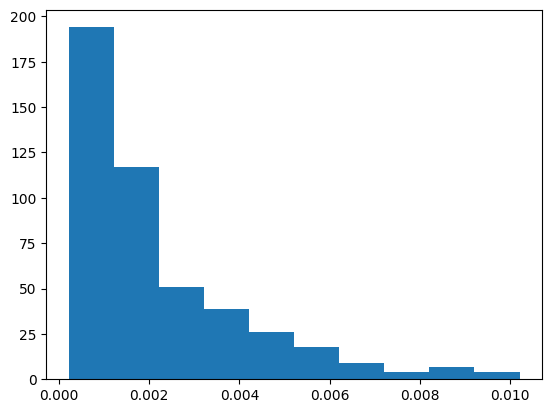

In [73]:
df['position_state_id'].value_counts(normalize=True).hist(grid=False, )

<Axes: >

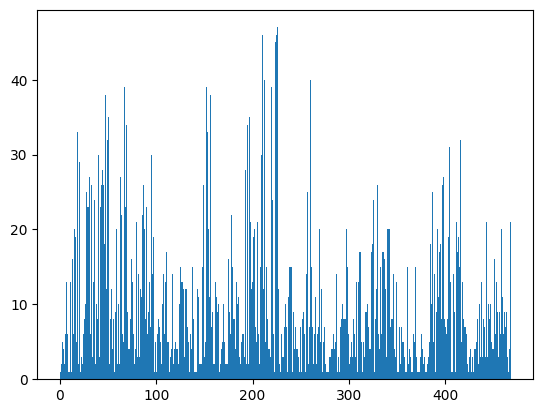

In [74]:
df['position_state_id'].hist(grid=False, bins=range(df['position_state_id'].nunique()))

## tokenized dataset

In [75]:
df['position_state_id'].head()

0     62
1    260
2    256
3    255
4    249
Name: position_state_id, dtype: int64

# Classes

In [76]:
from torch.nn.utils.rnn import pad_sequence

def collate_masked_batch(batch, pad_token_id=0):
    """
    Recebe uma lista de (input_ids, target_ids) e aplica padding para o maior comprimento.
    """
    input_ids, target_ids = zip(*batch)
    
    input_ids_padded = pad_sequence(input_ids, batch_first=True, padding_value=pad_token_id)
    target_ids_padded = pad_sequence(target_ids, batch_first=True, padding_value=-100)  # ignorado pela loss

    return input_ids_padded, target_ids_padded


In [77]:
import torch
from torch.utils.data import Dataset
import random

class TrajectoryMaskingDataset(Dataset):
    def __init__(self, full_sequence, mask_token_id, min_len=5, max_len=15, mask_prob=0.3):
        """
        full_sequence: lista 1D com todos os tokens da trajetória completa (ex: [12, 32, 99, ...])
        mask_token_id: ID reservado para o token [MASK]
        min_len, max_len: tamanho aleatório da janela de corte
        mask_prob: probabilidade de mascarar um token intermediário
        """
        self.full_sequence = full_sequence
        self.mask_token_id = mask_token_id
        self.min_len = min_len
        self.max_len = max_len
        self.mask_prob = mask_prob

        # Gera os índices de início para as janelas baseando-se no menor comprimento possível
        self.start_indices = list(range(0, len(full_sequence) - min_len))

    def __len__(self):
        return len(self.start_indices)

    def __getitem__(self, idx):
        start = self.start_indices[idx]
        seq_len = random.randint(self.min_len, self.max_len)
        end = min(start + seq_len, len(self.full_sequence))

        seq = self.full_sequence[start:end]

        input_ids = []
        target_ids = []

        for i, token in enumerate(seq):
            if i == 0 or i == len(seq) - 1:
                input_ids.append(token)
                target_ids.append(-100)
            elif random.random() < self.mask_prob:
                input_ids.append(self.mask_token_id)
                target_ids.append(token)
            else:
                input_ids.append(token)
                target_ids.append(-100)

        return torch.tensor(input_ids, dtype=torch.long), torch.tensor(target_ids, dtype=torch.long)


In [78]:
import torch
import torch.nn as nn

class TrajectoryBERT(nn.Module):
    def __init__(self, vocab_size, embed_size, num_layers, num_heads, hidden_dim, dropout=0.1, max_len=512, pad_token_id=0):
        super().__init__()
        self.pad_token_id = pad_token_id
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.position_embedding = nn.Embedding(max_len, embed_size)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_size,
            nhead=num_heads,
            dim_feedforward=hidden_dim,
            dropout=dropout,
            batch_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(embed_size, vocab_size)

    def forward(self, x):
        """
        x: [batch_size, seq_len] tensor de input_ids (com paddings, [MASK], etc.)
        """
        batch_size, seq_len = x.size()
        device = x.device

        # Gera posições e aplica embedding
        positions = torch.arange(seq_len, device=device).unsqueeze(0).expand(batch_size, seq_len)
        x_embed = self.embedding(x) + self.position_embedding(positions)

        # Gera attention_mask para ignorar os pads
        attention_mask = (x == self.pad_token_id)  # shape: [batch_size, seq_len], bool
        # -> Transformer usa True para ignorar posições (inverso do HuggingFace)

        # Aplica encoder
        encoded = self.encoder(x_embed, src_key_padding_mask=attention_mask)
        logits = self.fc_out(encoded)

        return logits


In [79]:
# Hiperparâmetros
embed_size = 512
num_layers = 2
num_heads = 4
hidden_dim = 1024
mask_token_id = df['position_state_id'].nunique()
pad_token_id = df['position_state_id'].nunique() + 1
vocab_size = pad_token_id + 1
seq_length = 7
dropout = 0.3
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_epochs = 30
# Simulando dados
sequences = df['position_state_id'].values

device, vocab_size

(device(type='cuda'), 471)

In [80]:
sequences

array([ 62, 260, 256, ..., 242, 199, 198])

In [81]:
mask_token_id = 469 + 1  # ou qualquer valor fora do intervalo real
pad_token_id = 0         # se 0 não for usado no vocabulário real

dataset = TrajectoryMaskingDataset(sequences, mask_token_id , max_len=seq_length)
loader = DataLoader(dataset, batch_size=16, shuffle=True, collate_fn=lambda x: collate_masked_batch(x, pad_token_id))


In [82]:
for x, y in loader:
    print("Input shape:", x.shape)
    print("Target shape:", y.shape)
    print("Input:", x[0])
    print("Target:", y[0])
    break


Input shape: torch.Size([16, 7])
Target shape: torch.Size([16, 7])
Input: tensor([403, 404, 408,  16,  13,   0,   0])
Target: tensor([-100, -100, -100, -100, -100, -100, -100])


In [83]:
np.max(sequences)

468

In [84]:
# Dataset e dataloaders
dataset = TrajectoryMaskingDataset(sequences, mask_token_id)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])

In [85]:
# Inicialização do modelo e treino
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = TrajectoryBERT(vocab_size, embed_size=embed_size, num_layers=num_layers, num_heads=num_heads, hidden_dim=hidden_dim,
                       dropout=dropout, pad_token_id=pad_token_id).to(device)

In [86]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss(ignore_index=-100)

In [87]:
import math

train_losses = []
val_losses = []
train_perplexities = []
val_perplexities = []

for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,
                          collate_fn=lambda x: collate_masked_batch(x, pad_token_id))
    
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False,
                        collate_fn=lambda x: collate_masked_batch(x, pad_token_id))
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        output = model(x)
        loss = criterion(output.view(-1, vocab_size), y.view(-1))
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x_val, y_val in val_loader:
            x_val, y_val = x_val.to(device), y_val.to(device)
            val_output = model(x_val)
            v_loss = criterion(val_output.view(-1, vocab_size), y_val.view(-1))
            val_loss += v_loss.item()

    # Cálculo médio das perdas
    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)

    # Cálculo da perplexidade
    train_ppl = math.exp(avg_train_loss)
    val_ppl = math.exp(avg_val_loss)

    # Armazenamento
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_perplexities.append(train_ppl)
    val_perplexities.append(val_ppl)

    if (epoch + 1) % max(1, num_epochs // 10) == 0 or (epoch + 1) == num_epochs:
        print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | "
            f"Train PPL: {train_ppl:.2f} | Val PPL: {val_ppl:.2f}")


Epoch 3/30 | Train Loss: 4.4378 | Val Loss: 3.6960 | Train PPL: 84.59 | Val PPL: 40.29
Epoch 6/30 | Train Loss: 2.3813 | Val Loss: 1.9889 | Train PPL: 10.82 | Val PPL: 7.31
Epoch 9/30 | Train Loss: 1.6955 | Val Loss: 1.3831 | Train PPL: 5.45 | Val PPL: 3.99
Epoch 12/30 | Train Loss: 1.3203 | Val Loss: 1.1235 | Train PPL: 3.74 | Val PPL: 3.08
Epoch 15/30 | Train Loss: 1.1536 | Val Loss: 0.9458 | Train PPL: 3.17 | Val PPL: 2.57
Epoch 18/30 | Train Loss: 1.0450 | Val Loss: 0.8134 | Train PPL: 2.84 | Val PPL: 2.26
Epoch 21/30 | Train Loss: 0.9320 | Val Loss: 0.7614 | Train PPL: 2.54 | Val PPL: 2.14
Epoch 24/30 | Train Loss: 0.8430 | Val Loss: 0.7423 | Train PPL: 2.32 | Val PPL: 2.10
Epoch 27/30 | Train Loss: 0.8052 | Val Loss: 0.7044 | Train PPL: 2.24 | Val PPL: 2.02
Epoch 30/30 | Train Loss: 0.7587 | Val Loss: 0.5909 | Train PPL: 2.14 | Val PPL: 1.81


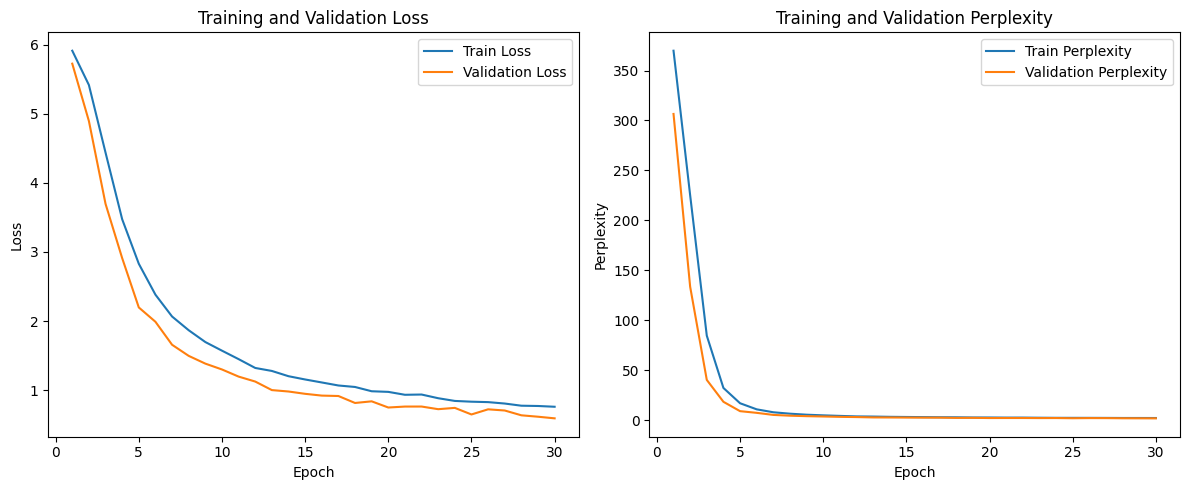

In [88]:
# Calcula perplexidade a partir das losses
train_perplexities = [np.exp(l) for l in train_losses]
val_perplexities = [np.exp(l) for l in val_losses]

# Plot da loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, int(num_epochs) + 1), train_losses, label='Train Loss')
plt.plot(range(1, int(num_epochs) + 1), val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
# plt.grid(True)

# Plot da perplexidade
plt.subplot(1, 2, 2)
plt.plot(range(1, int(num_epochs) + 1), train_perplexities, label='Train Perplexity')
plt.plot(range(1, int(num_epochs) + 1), val_perplexities, label='Validation Perplexity')
plt.xlabel('Epoch')
plt.ylabel('Perplexity')
plt.title('Training and Validation Perplexity')
plt.legend()
# plt.grid(True)

plt.tight_layout()
plt.show()


In [59]:
def visualize_predictions(model, x, y, mask_token_id, id_to_token=None):
    """
    Exibe a entrada x, os targets y e as previsões do modelo nas posições mascaradas.
    """
    if id_to_token is None:
        id_to_token = {}

    model.eval()
    device = next(model.parameters()).device
    x = x.unsqueeze(0).to(device)
    y = y.to(device)

    with torch.no_grad():
        logits = model(x)
        preds = torch.argmax(logits, dim=-1).squeeze(0).cpu()

    x = x.squeeze(0).cpu()
    y = y.cpu()

    # Vetor de entrada
    entrada_str = [id_to_token.get(tok.item(), str(tok.item())) for tok in x]
    target_str = [
        id_to_token.get(t.item(), str(t.item())) if t.item() != -100 else '-' for t in y
    ]

    print("\nEntrada (x):")
    print("[" + " ".join(entrada_str) + "]")

    print("\nTarget (y):")
    print("[" + " ".join(target_str) + "]\n")

    print(f"{'Posição':<8} {'Token em x':<14} {'Esperado (y)':<20} {'Previsto':<20} {'Correto'}")
    print("-" * 80)

    for i in range(len(x)):
        if y[i].item() == -100:
            continue

        input_token_id = x[i].item()
        target_token_id = y[i].item()
        predicted_token_id = preds[i].item()

        input_token = id_to_token.get(input_token_id, str(input_token_id))
        target_token = id_to_token.get(target_token_id, str(target_token_id))
        predicted_token = id_to_token.get(predicted_token_id, str(predicted_token_id))

        correto = "SIM" if target_token_id == predicted_token_id else "NÃO"
        print(f"{i:<8} {input_token:<14} {target_token:<20} {predicted_token:<20} {correto}")
    print("-" * 80)


In [60]:
x_batch, y_batch = next(iter(val_loader))
example_x = x_batch[0]
example_y = y_batch[0]

visualize_predictions(model, example_x, example_y, mask_token_id)


Entrada (x):
[15 404 403 415 470 152 470 149 28 0 0 0 0 0 0]

Target (y):
[- - - - 153 - 156 - - - - - - - -]

Posição  Token em x     Esperado (y)         Previsto             Correto
--------------------------------------------------------------------------------
4        470            153                  153                  SIM
6        470            156                  156                  SIM
--------------------------------------------------------------------------------


In [63]:
def expand_trajectory(model, start_token, end_token, mask_token_id, pad_token_id, max_len=12, id_to_token=None):
    """
    Expande uma sequência entre start_token e end_token, preenchendo iterativamente
    tokens intermediários e mostrando o histórico de predições.
    """
    device = next(model.parameters()).device
    sequence = [start_token, end_token]
    step = 1

    while len(sequence) < max_len:
        print(f"\n=== Etapa {step} ===")
        print("Sequência atual:", [id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])

        # Inserção de MASKs entre os pares
        new_sequence = []
        for i in range(len(sequence) - 1):
            new_sequence.append(sequence[i])
            new_sequence.append(mask_token_id)
        new_sequence.append(sequence[-1])
        sequence = new_sequence

        print("Com [MASK]:     ", [id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])

        # Predição
        input_tensor = torch.tensor(sequence, dtype=torch.long).unsqueeze(0).to(device)
        with torch.no_grad():
            logits = model(input_tensor)
            predictions = torch.argmax(logits, dim=-1).squeeze(0).cpu().tolist()

        # Substituição dos MASKs e exibição
        updated_sequence = []
        for i, token in enumerate(sequence):
            if token == mask_token_id:
                predicted_token = predictions[i]
                updated_sequence.append(predicted_token)
                print(f"Predição na posição {i}: {id_to_token.get(predicted_token, predicted_token) if id_to_token else predicted_token}")
            else:
                updated_sequence.append(token)

        sequence = updated_sequence
        print("Após predição: ", [id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])

        if len(sequence) >= max_len:
            print("\nLimite de comprimento atingido.")
            break

        step += 1

    print("\n=== Trajetória Final ===")
    print([id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])
    return sequence


In [65]:
start_token = 10
end_token = 55
max_len = 10

In [66]:
expand_trajectory(
    model,
    start_token=start_token,
    end_token=end_token,
    mask_token_id=mask_token_id,
    pad_token_id=pad_token_id,
    max_len=max_len,
    # id_to_token=id_to_token  # ou None
)


=== Etapa 1 ===
Sequência atual: [10, 55]
Com [MASK]:      [10, 470, 55]
Predição na posição 1: 5
Após predição:  [10, 5, 55]

=== Etapa 2 ===
Sequência atual: [10, 5, 55]
Com [MASK]:      [10, 470, 5, 470, 55]
Predição na posição 1: 5
Predição na posição 3: 64
Após predição:  [10, 5, 5, 64, 55]

=== Etapa 3 ===
Sequência atual: [10, 5, 5, 64, 55]
Com [MASK]:      [10, 470, 5, 470, 5, 470, 64, 470, 55]
Predição na posição 1: 5
Predição na posição 3: 6
Predição na posição 5: 6
Predição na posição 7: 65
Após predição:  [10, 5, 5, 6, 5, 6, 64, 65, 55]

=== Etapa 4 ===
Sequência atual: [10, 5, 5, 6, 5, 6, 64, 65, 55]
Com [MASK]:      [10, 470, 5, 470, 5, 470, 6, 470, 5, 470, 6, 470, 64, 470, 65, 470, 55]
Predição na posição 1: 5
Predição na posição 3: 6
Predição na posição 5: 11
Predição na posição 7: 11
Predição na posição 9: 11
Predição na posição 11: 11
Predição na posição 13: 55
Predição na posição 15: 5
Após predição:  [10, 5, 5, 6, 5, 11, 6, 11, 5, 11, 6, 11, 64, 55, 65, 5, 55]

Lim

[10, 5, 5, 6, 5, 11, 6, 11, 5, 11, 6, 11, 64, 55, 65, 5, 55]

In [58]:
# Suponha que você tenha treinado o modelo com vocabulário de IDs numéricos
start = [62,]  # exemplo de sequência inicial

generated_tokens = generate_sequence(model, start_sequence=start, max_new_tokens=5, vocab_size=vocab_size)
print("Tokens gerados:", generated_tokens)

Tokens gerados: [62, 236, 451, 236, 418, 410]


In [59]:
for tk in generated_tokens:
    print(f'{token_to_ps[tk]}')

CTYTRCRZKVYTLGNIIWLC
PZXOSTLYRCRZRUIZBJUQ
YORDEOWABFXYMHQXRCRZ
PZXOSTLYRCRZRUIZBJUQ
STLYKLTPCTYTBJUQRCRZ
STLYBJUQRUIZPZXORCRZ


## InputEmbeddings